> **Variante _sin recorte aleatorio_ de `other_experiments/02_train_resnet152.ipynb`.**
> Las entradas son siempre fondos de ojo **completos**: un `RandomResizedCrop(scale=(0.7, 1.0))` puede dejar fuera lesiones periféricas, el disco óptico o la mácula, y además deforma la proporción de la imagen. Aquí se sustituye por un **letterbox** (lado largo = `image_size`, relleno negro hasta cuadrado, sin deformar), aplicado **igual en train, val, test y Grad-CAM**.
> Todo lo demás es idéntico al notebook original (hiperparámetros, épocas, flip, rotación, `ColorJitter`, métricas), salvo el preprocesado (`TrainConfig.preprocessing = "letterbox"`) y el **criterio de selección** (ver abajo).
> **Criterio de selección = `val_loss` (se minimiza), no AUC.** El mejor checkpoint y el *early stopping* (paciencia 7) se basan en la pérdida focal de **validación** (`TrainConfig.selection_metric = "val_loss"`). Se usa `val_loss` y no `train_loss` porque la pérdida de entrenamiento baja casi siempre con las épocas y elegiría la más sobreajustada, mientras que `val_loss` sí mide generalización. AUC, F1 y accuracy se siguen calculando y reportando como métricas de evaluación.
> Salidas con sufijo `_nocrop` para no pisar el baseline original: checkpoint `best_resnet152_disease_risk_nocrop.pt`, historial `artifacts/logs/baseline_nocrop_history.json` y figuras en `artifacts/gradcam/nocrop/`.

# RFMiD — entrenar ResNet-152 (Disease_Risk), sin RandomResizedCrop


- Focal Loss (desbalance)
- Fine-tuning: `layer4` + `fc` entrenables; resto congelado
- 20 épocas por defecto; cada época imprime `train_loss` y `val_loss`

In [1]:
import json
import sys
from dataclasses import replace
from pathlib import Path

# Localiza retina_clasificacion/ aunque el cwd del kernel sea el padre Retina/
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
if _cwd.is_dir():
    _candidates.extend(sorted(path for path in _cwd.iterdir() if path.is_dir()))
PROJECT_ROOT = next(
    directory
    for directory in _candidates
    if (directory / "src" / "config.py").is_file() and (directory / "requirements.txt").is_file()
)
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != PROJECT_ROOT]
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import default_config
from src.data import PREPROCESSING_LETTERBOX, create_dataloaders
from src.evaluate import evaluate_loader, format_metrics
from src.train import get_device, load_best_checkpoint_for_eval, train_model

# Misma configuración que el baseline; cambian el preprocesado, el nombre del checkpoint
# y el criterio de selección (val_loss, a minimizar, en lugar de AUC)
BASELINE_NOCROP_CHECKPOINT_NAME = "best_resnet152_disease_risk_nocrop.pt"
config = replace(
    default_config(),
    preprocessing=PREPROCESSING_LETTERBOX,
    best_checkpoint_name=BASELINE_NOCROP_CHECKPOINT_NAME,
    selection_metric="val_loss",
)
print(
    f"epochs={config.epochs}, batch_size={config.batch_size}, device={get_device()}, "
    f"preprocessing={config.preprocessing}, selection_metric={config.selection_metric}"
)

epochs=20, batch_size=16, device=cpu, preprocessing=letterbox, selection_metric=val_loss


In [2]:
(
    train_loader,
    val_loader,
    test_loader,
    train_dataframe,
    val_dataframe,
    test_dataframe,
) = create_dataloaders(config)

for name, dataframe in [
    ("train", train_dataframe),
    ("val", val_dataframe),
    ("test", test_dataframe),
]:
    print(name, len(dataframe), dataframe["disease_risk"].value_counts().to_dict())

train 1920 {1: 1519, 0: 401}
val 640 {1: 506, 0: 134}
test 640 {1: 506, 0: 134}


In [5]:
# Entrena hasta 20 épocas (config.epochs). Por época: train_loss | val_loss | AUC | F1 | Acc
# Mejor checkpoint y early stopping según val_loss mínima (AUC/F1/Acc solo se reportan).
# Si ya existe el checkpoint nocrop NO se reentrena (ponlo a True para forzarlo).
FORCE_RETRAIN = True

baseline_checkpoint_path = config.checkpoint_dir / config.best_checkpoint_name
history_path = PROJECT_ROOT / "artifacts" / "logs" / "baseline_nocrop_history.json"
history_path.parent.mkdir(parents=True, exist_ok=True)

if FORCE_RETRAIN or not baseline_checkpoint_path.is_file():
    training_history: list[dict] = []
    train_model(train_loader, val_loader, config, history=training_history)
    history_path.write_text(json.dumps(training_history, indent=2), encoding="utf-8")
else:
    print(f"Checkpoint existente, se omite el entrenamiento: {baseline_checkpoint_path}")

Dispositivo: cpu
Backbone: ResNet-152 (no existe ResNet-150 en torchvision)
Épocas: 20
Parámetros entrenables: 14,966,785 / 58,145,857
Política de congelación:
  - conv1: congelado
  - bn1: congelado
  - relu: sin parámetros
  - maxpool: sin parámetros
  - layer1: congelado
  - layer2: congelado
  - layer3: congelado
  - layer4: entrenable
  - avgpool: sin parámetros
  - fc: entrenable


Epoch 01/20 | train_loss=0.0451 | val_loss=0.0294 | AUC=0.9407 | F1=0.9175 | Acc=0.8766
  → Nuevo mejor modelo (val_loss=0.0294) guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\checkpoints\best_resnet152_disease_risk_nocrop.pt


Epoch 02/20 | train_loss=0.0330 | val_loss=0.0289 | AUC=0.9400 | F1=0.8913 | Acc=0.8406
  → Nuevo mejor modelo (val_loss=0.0289) guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\checkpoints\best_resnet152_disease_risk_nocrop.pt


Epoch 03/20 | train_loss=0.0321 | val_loss=0.0312 | AUC=0.9315 | F1=0.9084 | Acc=0.8594


Epoch 04/20 | train_loss=0.0289 | val_loss=0.0522 | AUC=0.9167 | F1=0.9084 | Acc=0.8500


Epoch 05/20 | train_loss=0.0301 | val_loss=0.0327 | AUC=0.9209 | F1=0.8940 | Acc=0.8422


Epoch 06/20 | train_loss=0.0269 | val_loss=0.0329 | AUC=0.9397 | F1=0.8822 | Acc=0.8297


Epoch 07/20 | train_loss=0.0249 | val_loss=0.0327 | AUC=0.9302 | F1=0.9145 | Acc=0.8688


Epoch 08/20 | train_loss=0.0238 | val_loss=0.0339 | AUC=0.9298 | F1=0.9047 | Acc=0.8578


Epoch 09/20 | train_loss=0.0254 | val_loss=0.0392 | AUC=0.9283 | F1=0.9168 | Acc=0.8703
Early stopping en época 9 (paciencia=7)
Mejor val_loss de validación: 0.0289


In [6]:
device = get_device()
model = load_best_checkpoint_for_eval(config, device)

val_metrics = evaluate_loader(model, val_loader, device)
test_metrics = evaluate_loader(model, test_loader, device)
print(format_metrics(val_metrics, "val"))
print(format_metrics(test_metrics, "test"))

[val] AUC=0.9400 | F1=0.8913 | Acc=0.8406 | CM=[[120, 14], [88, 418]] (n=640, pos=506)
[test] AUC=0.9608 | F1=0.8991 | Acc=0.8531 | CM=[[127, 7], [87, 419]] (n=640, pos=506)


## Grad-CAM: ¿en qué se fija el modelo?

Grad-CAM (implementado a mano en `src/explain.py`) usa los *hooks* de la última capa convolucional (`layer4[-1]`): pondera cada mapa de activación por la media de su gradiente respecto al **logit de Disease_Risk** y aplica ReLU. El resultado es un mapa de calor de las regiones que *empujan* la predicción hacia "riesgo".

Se muestran ejemplos del **test** (umbral 0.5, el de las métricas de arriba): los verdaderos positivos (TP) y negativos (TN) más confiados, y los errores más confiados (FP y FN). Las imágenes se preprocesan con el **mismo letterbox** que usó el modelo (`preprocessing=config.preprocessing`); por eso las bandas negras superior/inferior son relleno. Las figuras se guardan en `artifacts/gradcam/nocrop/`.

In [7]:
import matplotlib.pyplot as plt

from src.evaluate import collect_predictions
from src.explain import compute_gradcam_samples, plot_gradcam_grid

GRADCAM_DIR = PROJECT_ROOT / "artifacts" / "gradcam" / "nocrop"
DECISION_THRESHOLD = 0.5

test_probabilities, test_labels, _ = collect_predictions(model, test_loader, device)
gradcam_samples = compute_gradcam_samples(
    model,
    test_dataframe,
    test_probabilities,
    test_labels,
    threshold=DECISION_THRESHOLD,
    image_size=config.image_size,
    examples_per_group=4,
    preprocessing=config.preprocessing,
)
print({group: sum(s['group'] == group for s in gradcam_samples) for group in ['TP', 'TN', 'FP', 'FN']})

{'TP': 4, 'TN': 4, 'FP': 4, 'FN': 4}


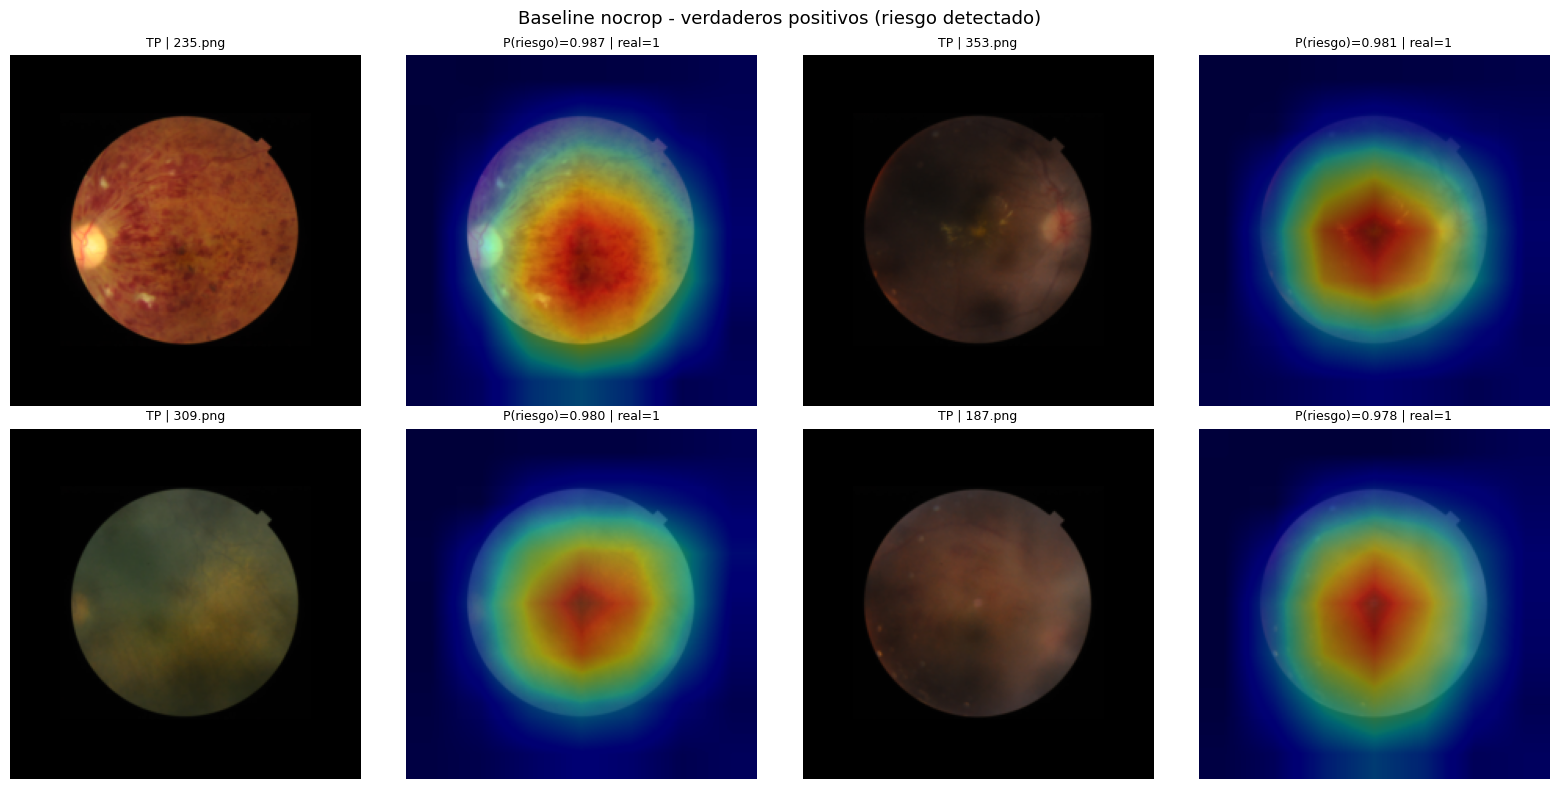

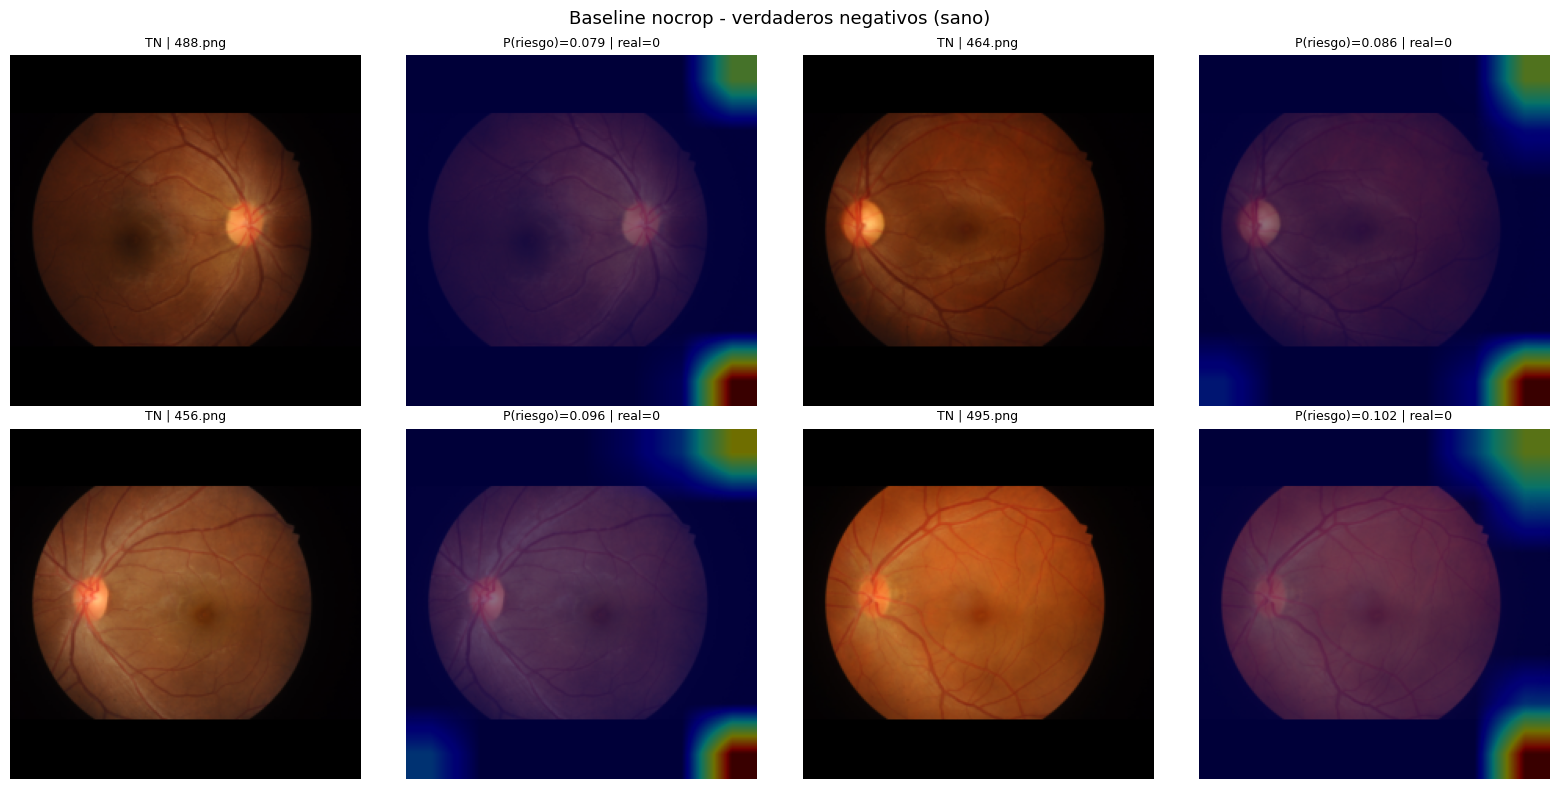

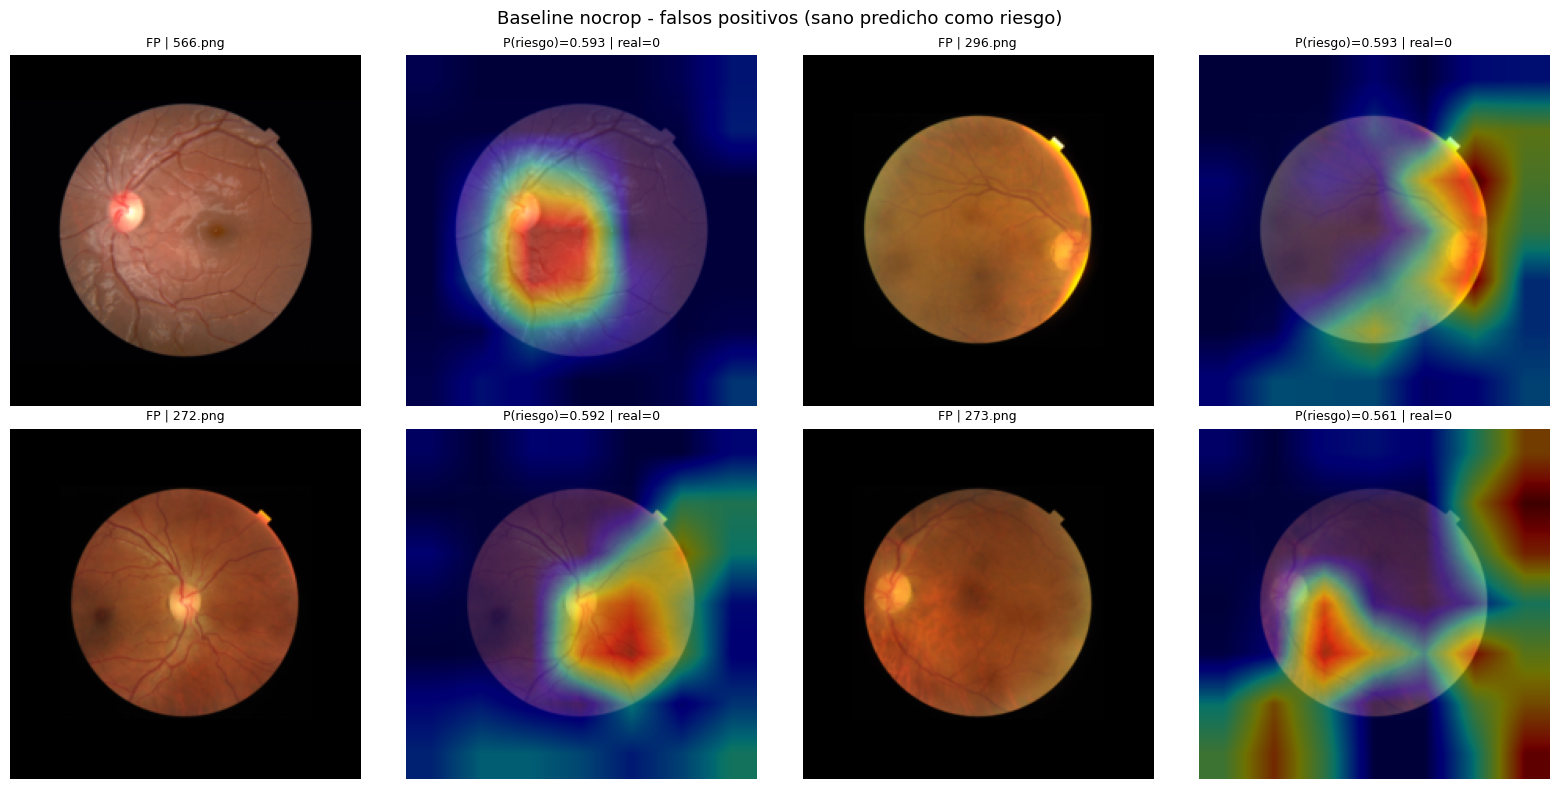

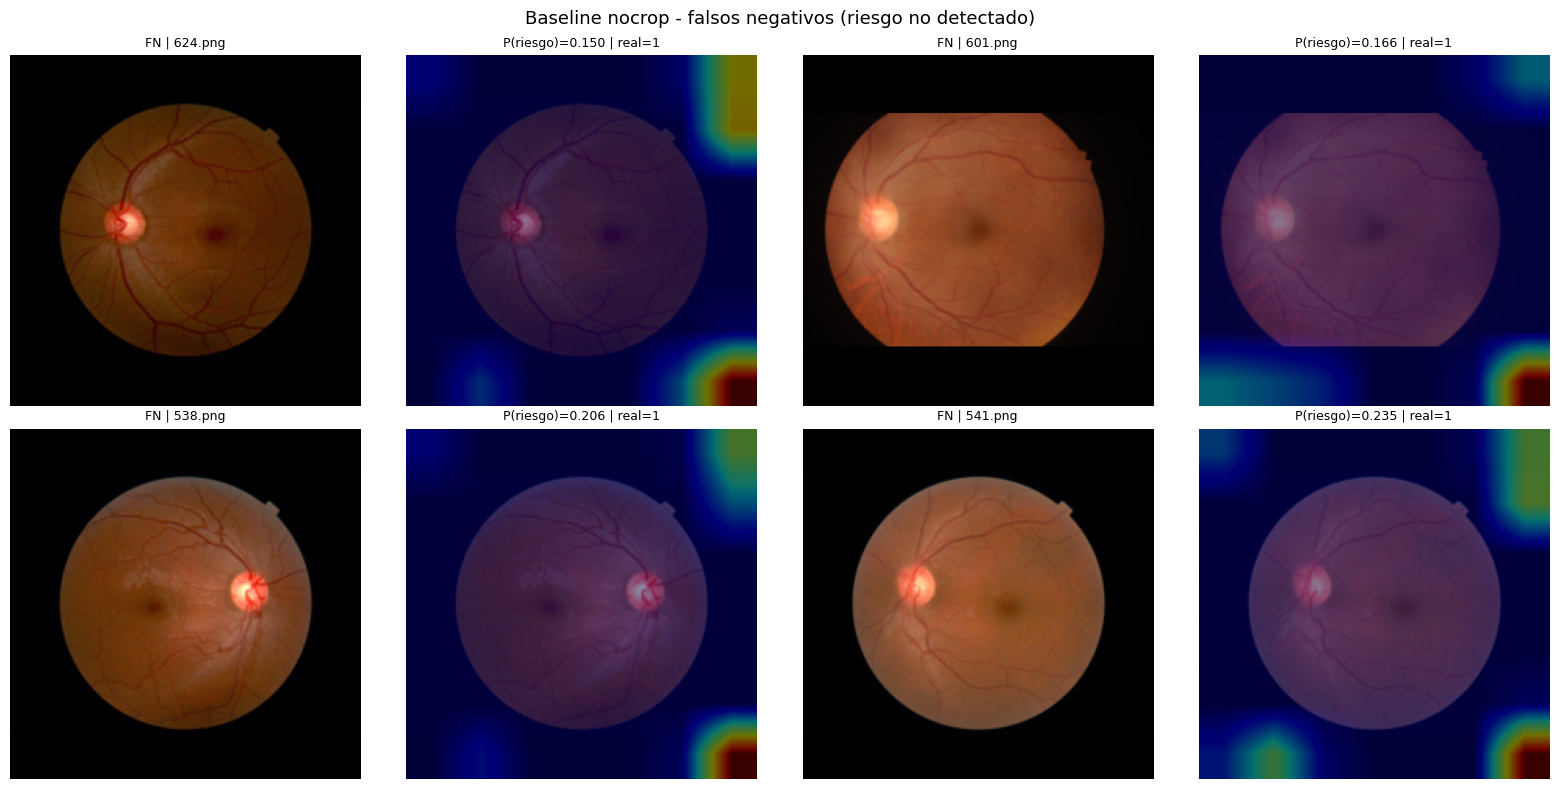

In [8]:
group_titles = {
    "TP": "Baseline nocrop - verdaderos positivos (riesgo detectado)",
    "TN": "Baseline nocrop - verdaderos negativos (sano)",
    "FP": "Baseline nocrop - falsos positivos (sano predicho como riesgo)",
    "FN": "Baseline nocrop - falsos negativos (riesgo no detectado)",
}
for group, group_title in group_titles.items():
    group_samples = [s for s in gradcam_samples if s["group"] == group]
    figure = plot_gradcam_grid(
        group_samples,
        title=group_title,
        save_path=GRADCAM_DIR / f"baseline_{group}.png",
    )
    if figure is not None:
        plt.show()

### Lectura cualitativa (baseline nocrop, test)

_Pendiente: la lectura del notebook original (`other_experiments/02_train_resnet152.ipynb`) describe las imágenes y errores del modelo con recorte aleatorio, así que no se copia aquí. Compara estas figuras con `artifacts/gradcam/baseline_*.png` una vez ejecutado el notebook._